In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Guaranteed URL for Nobel dataset from datacamp workspace content
url = "https://raw.githubusercontent.com/erikgregorywebb/nobel-prize-winners/master/nobel.csv"

try:
    nobel = pd.read_csv(url)
    print("Dataset successfully loaded!")
except Exception as e:
    try:
        fallback_url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2019/2019-05-14/nobel_winners.csv"
        nobel = pd.read_csv(fallback_url)
        # Rename columns to match standard nobel dataset expected names if necessary
        nobel = nobel.rename(columns={'birth_country': 'birth_country', 'gender': 'sex', 'laureate_type': 'laureate_type'})
        print("Dataset successfully loaded from fallback TidyTuesday URL!")
    except Exception as e2:
        print("Failed to load standard dataset. Please verify network access.")

if not nobel.empty:
    display(nobel.head())
    print(nobel.info())

Dataset successfully loaded from fallback TidyTuesday URL!


,prize_year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,160,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Male,Berlin University,Berlin,Germany,1911-03-01,Berlin,Germany
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,569,Individual,Sully Prudhomme,1839-03-16,Paris,France,Male,NaN,NaN,NaN,1907-09-07,Châtenay,France
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,293,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Male,Marburg University,Marburg,Germany,1917-03-31,Marburg,Germany
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,462,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Male,NaN,NaN,NaN,1910-10-30,Heiden,Switzerland
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,463,Individual,Frédéric Passy,1822-05-20,Paris,France,Male,NaN,NaN,NaN,1912-06-12,Paris,France


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 969 entries, 0 to 968
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   prize_year            969 non-null    int64 
 1   category              969 non-null    object
 2   prize                 969 non-null    object
 3   motivation            881 non-null    object
 4   prize_share           969 non-null    object
 5   laureate_id           969 non-null    int64 
 6   laureate_type         969 non-null    object
 7   full_name             969 non-null    object
 8   birth_date            938 non-null    object
 9   birth_city            941 non-null    object
 10  birth_country         943 non-null    object
 11  sex                   943 non-null    object
 12  organization_name     722 non-null    object
 13  organization_city     716 non-null    object
 14  organization_country  716 non-null    object
 15  death_date            617 non-null    ob

Most common gender: Male
Most common birth country: United States of America
Decade with the highest ratio of US-born winners: 2000.0s
Highest proportion of female laureates: 2010s in the category of Peace
First woman to win a Nobel Prize: Marie Curie, née Sklodowska (1903 in Physics)
Repeat winners: ['Comité international de la Croix Rouge (International Committee of the Red Cross)', 'Jack W. Szostak', 'Serge Haroche', 'David J. Wineland', 'Martin Karplus', 'Günter Blobel', 'Paul Ehrlich', 'Roderick MacKinnon', 'Richard Kuhn', 'Rudolf Ludwig Mössbauer', 'Walther Bothe', 'Randy W. Schekman', 'Thomas C. Südhof', 'Dale T. Mortensen', 'Office of the United Nations High Commissioner for Refugees (UNHCR)', 'Roger Y. Tsien', 'Abdus Salam', 'Stefan W. Hell', 'Mario R. Capecchi', 'Frederick Sanger', 'William Parry Murphy', 'Alvin E. Roth', 'Georges Charpak', 'Robert J. Lefkowitz', 'Adam G. Riess', 'Werner Forssmann', 'Saul Perlmutter', 'Adolf Friedrich Johann Butenandt', 'Albert Fert', 'John B

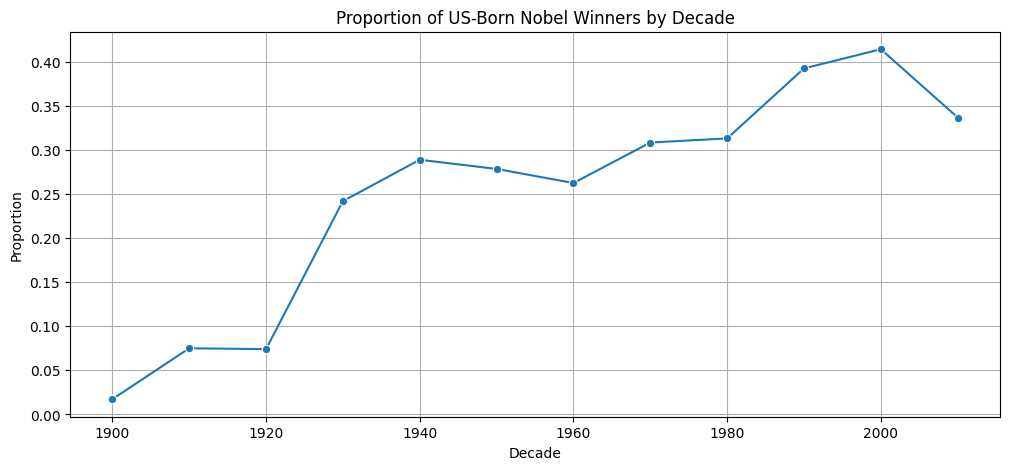

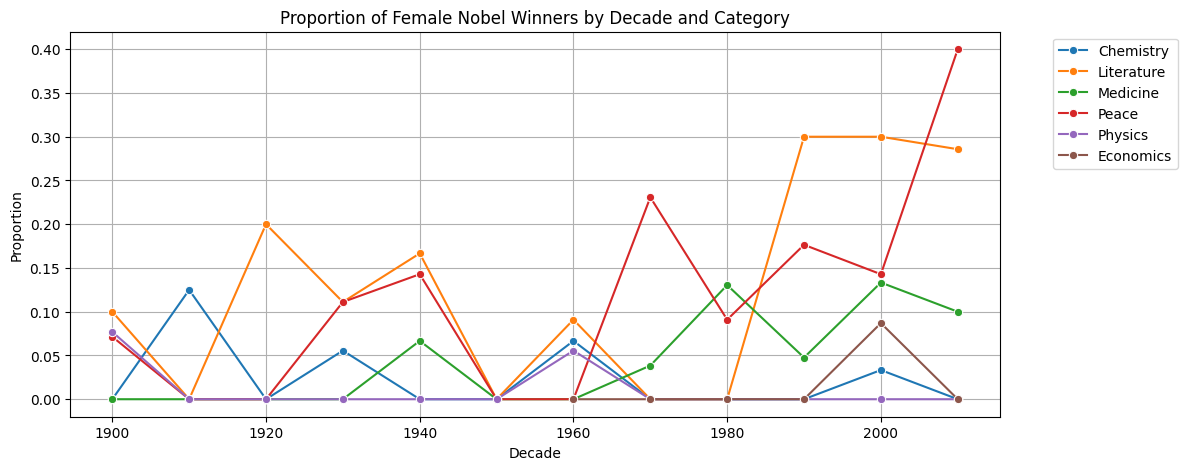

In [ ]:
# 1. Load the dataset and find the most common gender and birth country
top_gender = nobel['sex'].value_counts().index[0]
top_country = nobel['birth_country'].value_counts().index[0]
print(f"Most common gender: {top_gender}")
print(f"Most common birth country: {top_country}")

# 2. Identify the decade with the highest ratio of US-born winners
nobel['usa_born_winner'] = nobel['birth_country'] == 'United States of America'
nobel['decade'] = (np.floor(nobel['prize_year'] / 10) * 10).astype(int)
prop_usa_winners = nobel.groupby('decade', as_index=False)['usa_born_winner'].mean()
max_decade_usa = prop_usa_winners.loc[prop_usa_winners['usa_born_winner'].idxmax()]['decade']
print(f"Decade with the highest ratio of US-born winners: {max_decade_usa}s")

# 3. Find the decade and category with the highest proportion of female laureates
nobel['female_winner'] = nobel['sex'] == 'Female'
prop_female_winners = nobel.groupby(['decade', 'category'], as_index=False)['female_winner'].mean()
max_female_row = prop_female_winners.loc[prop_female_winners['female_winner'].idxmax()]
max_female_decade = max_female_row['decade']
max_female_category = max_female_row['category']
print(f"Highest proportion of female laureates: {max_female_decade}s in the category of {max_female_category}")

# 4. Find the first woman to win a Nobel Prize
female_laureates = nobel[nobel['sex'] == 'Female']
first_woman = female_laureates.sort_values('prize_year').iloc[0]
first_woman_name = first_woman['full_name']
first_woman_category = first_woman['category']
first_woman_year = first_woman['prize_year']
print(f"First woman to win a Nobel Prize: {first_woman_name} ({first_woman_year} in {first_woman_category})")

# 5. Determine repeat winners
laureate_counts = nobel['full_name'].value_counts()
repeat_winners = list(laureate_counts[laureate_counts > 1].index)
print(f"Repeat winners: {repeat_winners}")

# Visualizations
plt.figure(figsize=(12, 5))
sns.lineplot(data=prop_usa_winners, x='decade', y='usa_born_winner', marker='o')
plt.title('Proportion of US-Born Nobel Winners by Decade')
plt.ylabel('Proportion')
plt.xlabel('Decade')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
sns.lineplot(data=prop_female_winners, x='decade', y='female_winner', hue='category', marker='o')
plt.title('Proportion of Female Nobel Winners by Decade and Category')
plt.ylabel('Proportion')
plt.xlabel('Decade')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()